# Catalog coverage
Measures how Western, non-Western and international catalogs and Wikipedias cover individuals across polities.

In [1]:
import random
import tempfile
import numpy as np
import polars as pl
import duckdb
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import Image
from style import *

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'

INTERNATIONAL_QID = 'Q1072012'
BUCKET_YEARS = 50

apply_style()

In [2]:
CHINESE_WORLD = 'Chinese world'
TOP_N_DYNASTIES = 5


## Connect

In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='6GB'; SET threads=4; SET temp_directory='{tempfile.mkdtemp()}';")

## Load data
### Catalog categories

In [4]:
con.sql('''
    CREATE OR REPLACE TEMP TABLE place_present_state AS
    SELECT
        place.entity.qid,
        place.entity.label_en AS country_name,
        CASE
            WHEN place.present_day_state.name IS NOT NULL THEN place.present_day_state
            ELSE parent.present_day_state
        END               AS state
    FROM place
    LEFT JOIN place AS parent
           ON parent.entity.qid = place.country.qid
''')

identifier_properties = con.sql('''
    SELECT
        identifier.property.pid,
        identifier.property.label_en,
        identifier.issuer_country.name,
        place_present_state.country_name,
        place_present_state.state.is_western
    FROM identifier
    LEFT JOIN place_present_state
           ON place_present_state.qid = identifier.issuer_country.name
''').pl()

assert identifier_properties['pid'].n_unique() == identifier_properties.height
print('shape:', identifier_properties.shape)
print('with issuer country:', identifier_properties['name'].drop_nulls().len())
unresolved = identifier_properties.filter(pl.col('name').is_not_null() & pl.col('is_western').is_null())
print('issuer countries with no present-day state in V2:')
print(unresolved.group_by('name', 'country_name').len().sort('len', descending=True))
identifier_properties.drop_nulls('name').head()

shape: (10198, 5)
with issuer country: 6097
issuer countries with no present-day state in V2:
shape: (17, 3)
┌─────────────────────────────────┬───────────────────┬─────┐
│ name                            ┆ country_name      ┆ len │
│ ---                             ┆ ---               ┆ --- │
│ str                             ┆ str               ┆ u32 │
╞═════════════════════════════════╪═══════════════════╪═════╡
│ Q55                             ┆ Netherlands       ┆ 113 │
│ Q1246                           ┆ Kosovo            ┆ 3   │
│ Q13426199                       ┆ Republic of China ┆ 3   │
│ Q1747689                        ┆ Ancient Rome      ┆ 2   │
│ Q131964                         ┆ Austrian Empire   ┆ 2   │
│ …                               ┆ …                 ┆ …   │
│ Q41304                          ┆ Weimar Republic   ┆ 1   │
│ Q12548                          ┆ Holy Roman Empire ┆ 1   │
│ Q1206012                        ┆ German Reich      ┆ 1   │
│ 573b833c39f90af116871

pid,label_en,name,country_name,is_western
str,str,str,str,bool
"""P695""",null,"""Q1065""","""United Nations""",true
"""P247""",null,"""Q1065""","""United Nations""",true
"""P10632""","""OpenSanctions ID""","""Q1072012""","""internationality""",null
"""P13174""","""CamerounWeb person ID""","""Q1009""","""Cameroon""",false
"""P6751""",null,"""Q1016""","""Libya""",false


In [5]:
catalog_categories = identifier_properties.with_columns(
    pl.when(pl.col('name') == INTERNATIONAL_QID).then(pl.lit('international'))
    .when(pl.col('is_western')).then(pl.lit('western'))
    .when(~pl.col('is_western')).then(pl.lit('non_western'))
    .otherwise(None)
    .alias('category')
)

catalog_categories.group_by('category').len().sort('len', descending=True)

category,len
str,u32
"""western""",4417
null,4235
"""non_western""",1545
"""international""",1


### Wikipedia categories

In [6]:
wikipedia_categories = con.sql('''
    SELECT
        url,
        regexp_extract(url, 'https://([^.]+)\\.wikipedia\\.org', 1) AS language,
        CASE
            WHEN is_western     THEN 'western'
            WHEN NOT is_western THEN 'non_western'
        END AS category
    FROM sitelink
    WHERE url LIKE '%.wikipedia.org'
''').pl()

print('shape:', wikipedia_categories.shape)
print(wikipedia_categories.group_by('category').len().sort('len', descending=True))
wikipedia_categories.drop_nulls('category').sample(5, seed=SEED)

shape: (347, 3)
shape: (3, 2)
┌─────────────┬─────┐
│ category    ┆ len │
│ ---         ┆ --- │
│ str         ┆ u32 │
╞═════════════╪═════╡
│ null        ┆ 174 │
│ non_western ┆ 98  │
│ western     ┆ 75  │
└─────────────┴─────┘


url,language,category
str,str,str
"""https://zu.wikipedia.org""","""zu""","""non_western"""
"""https://he.wikipedia.org""","""he""","""non_western"""
"""https://yi.wikipedia.org""","""yi""","""non_western"""
"""https://ro.wikipedia.org""","""ro""","""western"""
"""https://sr.wikipedia.org""","""sr""","""western"""


### Catalog and Wikipedia flags

In [7]:
con.register('catalog_categories_df', catalog_categories.drop_nulls('category').select('pid', 'category'))
con.register('wikipedia_categories_df', wikipedia_categories.drop_nulls('category').select('url', 'category'))

con.sql('''
    CREATE OR REPLACE TEMP TABLE catalog_flags AS
    SELECT
        individual_identifier.qid,
        bool_or(catalog_categories_df.category = 'western')       AS has_western_catalog,
        bool_or(catalog_categories_df.category = 'non_western')   AS has_non_western_catalog,
        bool_or(catalog_categories_df.category = 'international') AS has_international_catalog
    FROM individual_identifier
    JOIN catalog_categories_df USING (pid)
    GROUP BY individual_identifier.qid
''')

con.sql('''
    CREATE OR REPLACE TEMP TABLE wikipedia_flags AS
    SELECT
        individual_sitelink.qid,
        bool_or(wikipedia_categories_df.category = 'western')     AS has_western_wikipedia,
        bool_or(wikipedia_categories_df.category = 'non_western') AS has_non_western_wikipedia
    FROM individual_sitelink
    JOIN wikipedia_categories_df
      ON wikipedia_categories_df.url = individual_sitelink.site_url
    GROUP BY individual_sitelink.qid
''')

for table in ['catalog_flags', 'wikipedia_flags']:
    n, n_unique = con.sql(f'SELECT COUNT(*), COUNT(DISTINCT qid) FROM {table}').fetchone()
    assert n == n_unique
    print(f'{table}: {n:,} individuals')
con.sql('SELECT * FROM catalog_flags USING SAMPLE reservoir(5 ROWS) REPEATABLE (42)').pl()

catalog_flags: 5,438,602 individuals
wikipedia_flags: 4,714,476 individuals


qid,has_western_catalog,has_non_western_catalog,has_international_catalog
str,bool,bool,bool
"""Q108837667""",true,false,false
"""Q115628966""",true,false,false
"""Q138017230""",false,true,false
"""Q4758439""",true,true,false
"""Q87084117""",true,true,true


### Polity matches and coverage labels
Polity = polities of the active life (life-stage polities, v3.2); an individual has a polity if any of the three life-stage lists is non-empty. World = Cliopatria polity world (Japan, Korea, Chinese world, Muslim world, ...) of any active-life polity, so that successive polities of one region are grouped over the long run.

In [8]:
con.sql('''
    CREATE OR REPLACE TEMP TABLE polity_matches AS
    SELECT
        entity.qid,
        unnest(list_transform(active_life_polity, m -> m.polity.name)) AS polity_name
    FROM individual_enriched
    WHERE len(active_life_polity) > 0
''')

con.sql('''
    CREATE OR REPLACE TEMP TABLE world_matches AS
    SELECT DISTINCT
        entity.qid,
        unnest(list_distinct(flatten(list_transform(active_life_polity, m -> m.polity.world)))) AS world_name
    FROM individual_enriched
    WHERE len(active_life_polity) > 0
''')

con.sql('''
    CREATE OR REPLACE TEMP TABLE matched_individual_flags AS
    SELECT
        individual_enriched.entity.qid,
        individual_enriched.start_of_active_life.year                       AS active_life_start,
        individual.birth_date[1].year                           AS birth_year,
        COALESCE(catalog_flags.has_western_catalog, false)         AS western_catalog,
        COALESCE(catalog_flags.has_non_western_catalog, false)     AS non_western_catalog,
        COALESCE(catalog_flags.has_international_catalog, false)   AS international_catalog,
        COALESCE(wikipedia_flags.has_western_wikipedia, false)       AS western_wiki,
        COALESCE(wikipedia_flags.has_non_western_wikipedia, false)   AS non_western_wiki
    FROM individual_enriched
    JOIN individual
      ON individual.entity.qid = individual_enriched.entity.qid
    LEFT JOIN catalog_flags
           ON catalog_flags.qid = individual_enriched.entity.qid
    LEFT JOIN wikipedia_flags
           ON wikipedia_flags.qid = individual_enriched.entity.qid
    WHERE len(individual_enriched.pre_active_life_polity) > 0
       OR len(individual_enriched.active_life_polity) > 0
       OR len(individual_enriched.post_active_life_polity) > 0
''')

con.sql('''
    CREATE OR REPLACE TEMP TABLE individual_coverage AS
    SELECT
        qid,
        active_life_start,
        birth_year,
        western_catalog OR western_wiki           AS any_western,
        non_western_catalog OR non_western_wiki   AS any_non_western,
        CASE
            WHEN western_catalog AND NOT non_western_catalog THEN 'western_catalog_only'
            WHEN non_western_catalog AND NOT western_catalog THEN 'non_western_catalog_only'
            WHEN western_catalog AND non_western_catalog     THEN 'both_catalogs'
            WHEN international_catalog                       THEN 'international_only'
            WHEN western_wiki AND NOT non_western_wiki       THEN 'western_wikipedia_only'
            WHEN non_western_wiki AND NOT western_wiki       THEN 'non_western_wikipedia_only'
            WHEN western_wiki AND non_western_wiki           THEN 'both_wikipedias'
            ELSE 'no_catalog_no_wikipedia'
        END AS coverage
    FROM matched_individual_flags
''')

n_matches, n_matched = con.sql('SELECT COUNT(*), COUNT(DISTINCT qid) FROM polity_matches').fetchone()
n_coverage = con.sql('SELECT COUNT(*) FROM individual_coverage').fetchone()[0]
assert n_coverage >= n_matched
print(f'active-life polity matches: {n_matches:,} rows, {n_matched:,} individuals')
print(f'individuals with a life-stage polity: {n_coverage:,}')
con.sql('SELECT * FROM individual_coverage USING SAMPLE reservoir(5 ROWS) REPEATABLE (42)').pl()

active-life polity matches: 4,758,740 rows, 3,624,596 individuals
individuals with a life-stage polity: 3,631,573


qid,active_life_start,birth_year,any_western,any_non_western,coverage
str,i64,i64,bool,bool,str
"""Q101112772""",1964,1920,true,false,"""western_catalog_only"""
"""Q101584390""",1980,2000,false,true,"""non_western_catalog_only"""
"""Q104243631""",1922,1880,true,true,"""both_wikipedias"""
"""Q104715955""",1919,1878,true,false,"""western_catalog_only"""
"""Q104713222""",1921,1888,true,false,"""western_wikipedia_only"""


### Exclusive coverage by birth year, per polity world

In [9]:
PANEL_WORLDS = ['Chinese world', 'Japan', 'Korea']
BIRTH_YEAR_MIN, BIRTH_YEAR_MAX = 1300, 1849

panel_counts = con.sql('''
    SELECT
        world_matches.world_name,
        CAST(FLOOR(individual_coverage.birth_year / $bucket_years) * $bucket_years AS INTEGER) AS bucket,
        CASE
            WHEN individual_coverage.any_western AND NOT individual_coverage.any_non_western THEN 'Western only'
            WHEN individual_coverage.any_non_western AND NOT individual_coverage.any_western THEN 'Non-Western only'
            ELSE 'other'
        END      AS exclusive_group,
        COUNT(*) AS n
    FROM world_matches
    JOIN individual_coverage USING (qid)
    WHERE list_contains($panel, world_matches.world_name)
      AND individual_coverage.birth_year >= $birth_year_min
      AND individual_coverage.birth_year <= $birth_year_max
    GROUP BY world_matches.world_name, bucket, exclusive_group
''', params={
    'panel': PANEL_WORLDS,
    'bucket_years': BUCKET_YEARS,
    'birth_year_min': BIRTH_YEAR_MIN,
    'birth_year_max': BIRTH_YEAR_MAX,
}).pl()

print('shape:', panel_counts.shape)
panel_counts.head()

shape: (97, 4)


world_name,bucket,exclusive_group,n
str,i32,str,i64
"""Chinese world""",1650,"""other""",3195
"""Chinese world""",1800,"""other""",6802
"""Chinese world""",1600,"""Non-Western only""",933
"""Chinese world""",1700,"""other""",3498
"""Chinese world""",1350,"""Non-Western only""",554


### Chinese polities and their catalogs

In [10]:
chinese_polities = con.sql('''
    SELECT name, MIN(territory.start_year) AS start_year
    FROM polity, unnest(territories) AS unnested(territory)
    WHERE list_contains(world, $world)
    GROUP BY name
''', params={'world': CHINESE_WORLD}).pl()
print(f'polities of the {CHINESE_WORLD}: {chinese_polities.height}')

con.register('catalog_names_df', catalog_categories.select('pid', 'label_en', 'country_name'))
catalog_names = con.sql('''
    SELECT DISTINCT
        polity_matches.qid,
        polity_matches.polity_name,
        catalog_names_df.label_en,
        catalog_names_df.country_name
    FROM polity_matches
    JOIN individual_identifier USING (qid)
    JOIN catalog_names_df USING (pid)
    WHERE list_contains($targets, polity_matches.polity_name)
      AND catalog_names_df.label_en IS NOT NULL
''', params={'targets': chinese_polities['name'].to_list()}).pl()

con.close()
print('shape:', catalog_names.shape)
catalog_names.head()

polities of the Chinese world: 24


shape: (82183, 4)


qid,polity_name,label_en,country_name
str,str,str,str
"""Q10565509""","""Qing Dynasty""","""IdRef ID""","""France"""
"""Q10565627""","""Qing Dynasty""","""Google Knowledge Graph ID""",null
"""Q10565667""","""Southern Song""","""Google Knowledge Graph ID""",null
"""Q10565528""","""Southern Song""","""Geni.com profile ID""",null
"""Q10565692""","""Qing Dynasty""","""ISNI""",null


## Preprocessing

### Birth periods

In [11]:
last_complete_bucket = (BIRTH_YEAR_MAX + 1) // BUCKET_YEARS * BUCKET_YEARS - BUCKET_YEARS
print('rows before filter:', panel_counts.height)
world_panel = (
    panel_counts
    .filter(pl.col('exclusive_group') != 'other')
    .filter(pl.col('bucket') <= last_complete_bucket)
    .pivot(values='n', index=['world_name', 'bucket'], on='exclusive_group', aggregate_function='sum')
    .fill_null(0)
    .sort('world_name', 'bucket')
)
print('rows after filter: ', world_panel.height)
world_panel.head()

rows before filter: 97
rows after filter:  33


world_name,bucket,Non-Western only,Western only
str,i32,i64,i64
"""Chinese world""",1300,274,10
"""Chinese world""",1350,554,9
"""Chinese world""",1400,2610,4
"""Chinese world""",1450,2122,9
"""Chinese world""",1500,3257,19


### Sankey flows

In [12]:
TOP_N_CATALOGS = 12
MIN_RIBBON_SIZE = 5
WIKI_NAME_PATTERN = '(?i)wikipedia|wikidata|wikimedia|wikisource'

chinese_catalog_links = (
    catalog_names
    .filter(~pl.col('label_en').str.contains(WIKI_NAME_PATTERN))
    .select('qid', 'label_en', 'polity_name')
    .unique()
)

dynasty_ranking = (
    chinese_catalog_links
    .group_by('polity_name')
    .agg(pl.col('qid').n_unique().alias('individual_count'))
    .sort('individual_count', 'polity_name', descending=[True, False])
)
print(dynasty_ranking.head(10))

DYNASTY_ORDER = (
    chinese_polities
    .filter(pl.col('name').is_in(dynasty_ranking.head(TOP_N_DYNASTIES)['polity_name'].to_list()))
    .sort('start_year')['name'].to_list()
)
palette = list(CHINESE_POLITY_COLORS.values())
DYNASTY_COLORS = {
    dynasty: palette[round(i * (len(palette) - 1) / (len(DYNASTY_ORDER) - 1))]
    for i, dynasty in enumerate(DYNASTY_ORDER)
}

chinese_individual_catalog_polity = chinese_catalog_links.filter(pl.col('polity_name').is_in(DYNASTY_ORDER))

top_catalogs = (
    chinese_individual_catalog_polity
    .group_by('label_en')
    .agg(pl.col('qid').n_unique().alias('individual_count'))
    .sort('individual_count', 'label_en', descending=[True, False])
    .head(TOP_N_CATALOGS)['label_en'].to_list()
)
CATALOG_ORDER = top_catalogs + ['Other catalogs']

sankey_flows = (
    chinese_individual_catalog_polity
    .with_columns(
        pl.when(pl.col('label_en').is_in(top_catalogs)).then(pl.col('label_en'))
        .otherwise(pl.lit('Other catalogs')).alias('catalog_group')
    )
    .group_by('catalog_group', 'polity_name')
    .agg(pl.col('qid').n_unique().alias('individual_count'))
    .filter(pl.col('individual_count') >= MIN_RIBBON_SIZE)
    .sort('catalog_group', 'polity_name')
)

print('chinese_individual_catalog_polity shape:', chinese_individual_catalog_polity.shape)
print('sankey_flows shape:', sankey_flows.shape)
sankey_flows.head()

shape: (10, 2)
┌───────────────┬──────────────────┐
│ polity_name   ┆ individual_count │
│ ---           ┆ ---              │
│ str           ┆ u32              │
╞═══════════════╪══════════════════╡
│ Ming Dynasty  ┆ 9697             │
│ Qing Dynasty  ┆ 9496             │
│ Southern Song ┆ 6243             │
│ Tang Dynasty  ┆ 6242             │
│ Northern Song ┆ 1120             │
│ Yuan Dynasty  ┆ 994              │
│ Han Dynasty   ┆ 675              │
│ Western Jin   ┆ 421              │
│ Northern Wei  ┆ 386              │
│ Sui Dynasty   ┆ 316              │
└───────────────┴──────────────────┘
chinese_individual_catalog_polity shape: (71864, 3)
sankey_flows shape: (61, 3)


catalog_group,polity_name,individual_count
str,str,u32
"""Encyclopedia of China (Third E…","""Ming Dynasty""",281
"""Encyclopedia of China (Third E…","""Northern Song""",47
"""Encyclopedia of China (Third E…","""Qing Dynasty""",671
"""Encyclopedia of China (Third E…","""Southern Song""",169
"""Encyclopedia of China (Third E…","""Tang Dynasty""",287


## Figures

### Figure 7: Individuals covered only by Western or only by non-Western catalogs

#### Data plotted

In [13]:
print('shape:', world_panel.shape)
world_totals = (
    world_panel
    .group_by('world_name')
    .agg(pl.col('Non-Western only').sum(), pl.col('Western only').sum())
    .with_columns((pl.col('Non-Western only') / pl.col('Western only')).round(1).alias('ratio'))
    .sort('world_name')
)
print(world_totals)
world_panel

shape: (33, 4)
shape: (3, 4)
┌───────────────┬──────────────────┬──────────────┬───────┐
│ world_name    ┆ Non-Western only ┆ Western only ┆ ratio │
│ ---           ┆ ---              ┆ ---          ┆ ---   │
│ str           ┆ i64              ┆ i64          ┆ f64   │
╞═══════════════╪══════════════════╪══════════════╪═══════╡
│ Chinese world ┆ 15638            ┆ 435          ┆ 35.9  │
│ Japan         ┆ 7880             ┆ 244          ┆ 32.3  │
│ Korea         ┆ 1848             ┆ 37           ┆ 49.9  │
└───────────────┴──────────────────┴──────────────┴───────┘


world_name,bucket,Non-Western only,Western only
str,i32,i64,i64
"""Chinese world""",1300,274,10
"""Chinese world""",1350,554,9
"""Chinese world""",1400,2610,4
"""Chinese world""",1450,2122,9
"""Chinese world""",1500,3257,19
…,…,…,…
"""Korea""",1600,180,2
"""Korea""",1650,151,3
"""Korea""",1700,161,6


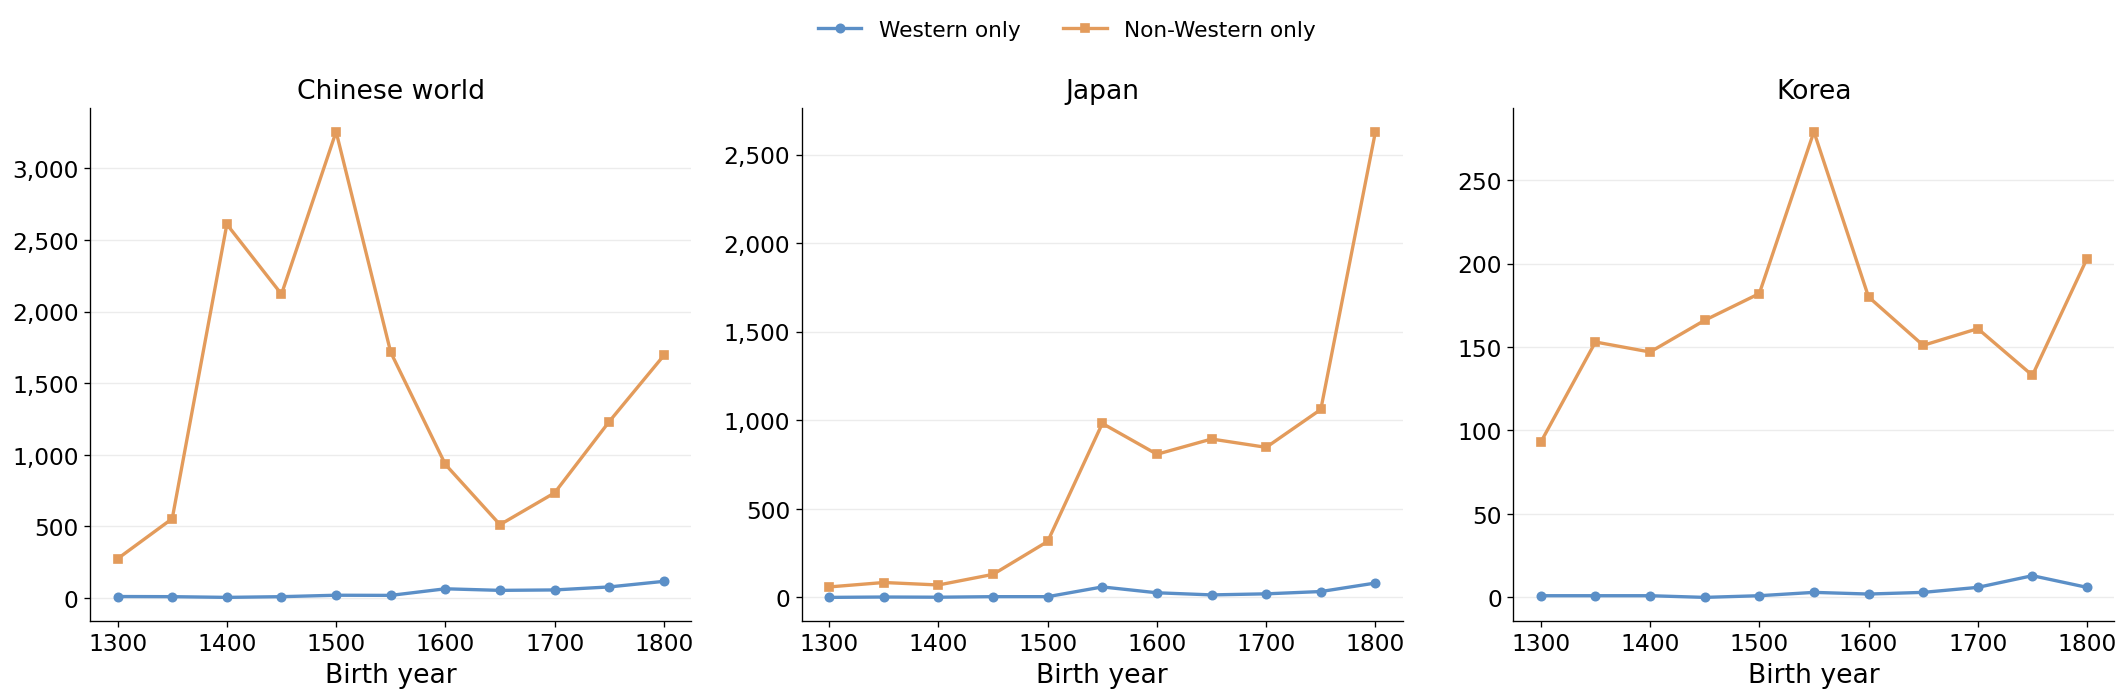

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True)
for ax, world in zip(axes, PANEL_WORLDS):
    rows = world_panel.filter(pl.col('world_name') == world)
    ax.plot(rows['bucket'], rows['Western only'], color=COVERAGE_COLORS['western_catalog'], marker='o', ms=5, label='Western only')
    ax.plot(rows['bucket'], rows['Non-Western only'], color=COVERAGE_COLORS['non_western_catalog'], marker='s', ms=5, label='Non-Western only')
    ax.set_title(world)
    ax.grid(axis='y')
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_xticks(range(1300, 1801, 100))
    ax.set_xlabel('Birth year')
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
plt.show()

### Figure S6: Top catalogs → Chinese dynasties

#### Data plotted

In [15]:
print('shape:', sankey_flows.shape)
sankey_flows

shape: (61, 3)


catalog_group,polity_name,individual_count
str,str,u32
"""Encyclopedia of China (Third E…","""Ming Dynasty""",281
"""Encyclopedia of China (Third E…","""Northern Song""",47
"""Encyclopedia of China (Third E…","""Qing Dynasty""",671
"""Encyclopedia of China (Third E…","""Southern Song""",169
"""Encyclopedia of China (Third E…","""Tang Dynasty""",287
…,…,…
"""Yale LUX ID""","""Ming Dynasty""",579
"""Yale LUX ID""","""Northern Song""",54
"""Yale LUX ID""","""Qing Dynasty""",1657


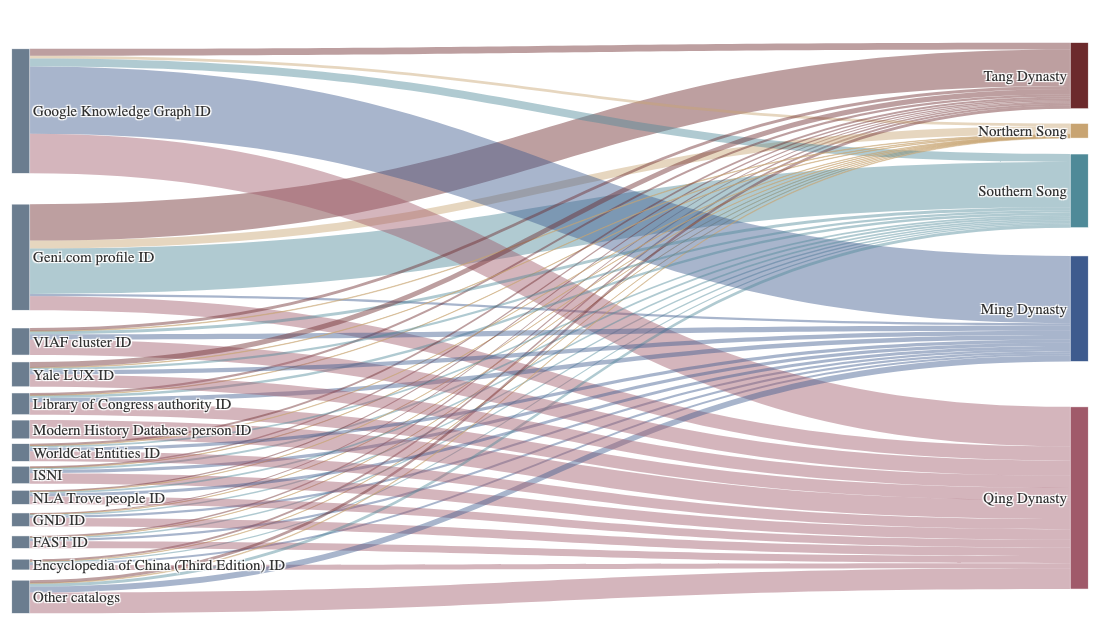

In [16]:
catalog_index = {catalog: i for i, catalog in enumerate(CATALOG_ORDER)}
polity_index = {polity: len(CATALOG_ORDER) + i for i, polity in enumerate(DYNASTY_ORDER)}
n_catalogs = len(CATALOG_ORDER)

def node_centers(frame, column, order):
    totals = frame.group_by(column).agg(pl.col('individual_count').sum())
    lookup = dict(totals.iter_rows())
    fractions = np.array([lookup.get(name, 0) for name in order], dtype=float)
    fractions = np.maximum(fractions / fractions.sum(), 0.04)
    fractions /= fractions.sum()
    return list(0.02 + 0.96 * (np.cumsum(fractions) - fractions / 2))

fig = go.Figure(go.Sankey(
    arrangement='fixed',
    node=dict(
        pad=14, thickness=18, line=dict(color=BACKGROUND_COLOR, width=0.5),
        label=CATALOG_ORDER + DYNASTY_ORDER,
        color=[NEUTRAL_BAR_COLOR] * n_catalogs + [DYNASTY_COLORS[m] for m in DYNASTY_ORDER],
        x=[0.01] * n_catalogs + [0.99] * len(DYNASTY_ORDER),
        y=node_centers(sankey_flows, 'catalog_group', CATALOG_ORDER) + node_centers(sankey_flows, 'polity_name', DYNASTY_ORDER),
    ),
    link=dict(
        source=[catalog_index[c] for c in sankey_flows['catalog_group']],
        target=[polity_index[m] for m in sankey_flows['polity_name']],
        value=sankey_flows['individual_count'].to_list(),
        color=[hex_to_rgba(DYNASTY_COLORS[m], 0.45) for m in sankey_flows['polity_name']],
    ),
))
fig.update_layout(font=PLOTLY_FONT, paper_bgcolor=BACKGROUND_COLOR, margin=dict(l=10, r=10, t=20, b=10))
Image(fig.to_image(format='png', width=1100, height=640, scale=1))